# Linear Regression 2.2 - Predicting Goals Scored by a Team (FIFA World Cup 2026)
## Data checking, feature engineering, EDA, modelling and evaluation (Nabin Pandey)

Target: goals scored by one team in one match. 208 rows (104 matches x 2 teams), 8 explanatory variables, all known before kick-off.



In [52]:
%pip install pandas numpy matplotlib seaborn statsmodels scikit-learn


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Import libraries

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [54]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs('figures', exist_ok=True)
np.random.seed(42)

## 2. Load the data

In [55]:
team_matches = pd.read_csv('../processed/team_matches_clean.csv', parse_dates=['date'])
matches = pd.read_csv('../processed/matches_clean.csv')
team_info = pd.read_csv('../processed/team_info.csv').set_index('team')

# add kick-off time from the match table
team_matches = team_matches.merge(matches[['match_id', 'kickoff_local']], on='match_id', how='left')

print(team_matches.shape, matches.shape, team_info.shape)
team_matches.head()

(208, 19) (104, 21) (48, 4)


,row_id,match_id,date,round,matchweek,team,opponent,goals_for,goals_against,is_listed_home,team_is_host,opponent_is_host,attendance,venue,referee,is_knockout,went_to_extra_time,went_to_pens,kickoff_local
0,1,1,2026-06-11,Group stage,1.0,Mexico,South Africa,2,0,True,True,False,80824,Estadio Banorte,Wilton Sampaio,False,False,False,13:00
1,2,1,2026-06-11,Group stage,1.0,South Africa,Mexico,0,2,False,False,True,80824,Estadio Banorte,Wilton Sampaio,False,False,False,13:00
2,3,2,2026-06-11,Group stage,1.0,Korea Republic,Czechia,2,1,True,False,False,44985,Estadio Akron,Amin Omar,False,False,False,20:00
3,4,2,2026-06-11,Group stage,1.0,Czechia,Korea Republic,1,2,False,False,False,44985,Estadio Akron,Amin Omar,False,False,False,20:00
4,5,3,2026-06-12,Group stage,1.0,Canada,Bosnia–Herz,1,1,True,True,False,43002,BMO Field,Facundo Tello,False,False,False,15:00


## 3. Checking the dataset

In [56]:
print('rows:', len(team_matches), '| matches:', team_matches['match_id'].nunique())
print('every match has 2 rows:', (team_matches.groupby('match_id').size() == 2).all())
print('missing values:', team_matches[['team', 'opponent', 'goals_for', 'goals_against']].isna().sum().sum())
print('teams not in team_info:', set(team_matches['team']) - set(team_info.index))
print('missing kick-off times:', team_matches['kickoff_local'].isna().sum())

rows: 208 | matches: 104
every match has 2 rows: True
missing values: 0
teams not in team_info: set()
missing kick-off times: 0


In [57]:
# goals_for of one row must equal goals_against of the other row in the same match
check = team_matches.merge(team_matches, on='match_id', suffixes=('', '_other'))
check = check[check['team'] != check['team_other']]
print('goals consistent:', (check['goals_for'] == check['goals_against_other']).all())

goals consistent: True


## 4. Building a new dataset

Form variables are calculated only from matches played **before** the current one.

A team's first match has no history. Using 0 would wrongly say "this team scores no goals", so we start every team
at the tournament average and update it as matches are played:
`form = (sum of previous values + overall average) / (number of previous matches + 1)`.

In [58]:
avg_goals = team_matches['goals_for'].mean()   # about 1.48 goals per team per match

def form(values):
    return (sum(values) + avg_goals) / (len(values) + 1)

strong = team_info['confederation'].isin(['UEFA', 'CONMEBOL']).astype(int)
high_altitude_venues = ['Estadio Banorte', 'Estadio Akron']   # Mexico City ~2,240 m, Guadalajara ~1,560 m

def kickoff_hour(text):
    hh, mm = text.split(':')
    return int(hh) + int(mm) / 60

In [59]:
def make_row(r, team_hist, opp_hist):
    t, o = r['team'], r['opponent']
    return {
        'row_id': r['row_id'], 'match_id': r['match_id'], 'team': t, 'opponent': o,
        'x1_rank_diff': team_info.loc[o, 'fifa_rank'] - team_info.loc[t, 'fifa_rank'],
        'x2_host_advantage': int(r['team_is_host']) - int(r['opponent_is_host']),
        'x3_strong_conf_diff': strong[t] - strong[o],
        'x4_kickoff_hour': kickoff_hour(r['kickoff_local']),
        'x5_attack_form': form([h['gf'] for h in team_hist]),
        'x6_opp_defence_form': form([h['ga'] for h in opp_hist]),
        'x7_is_knockout': int(r['is_knockout']),
        'x8_high_altitude': int(r['venue'] in high_altitude_venues),
        'y_goals': r['goals_for'],
    }

In [60]:
history = {team: [] for team in team_info.index}
rows = []

for match_id, pair in team_matches.sort_values(['date', 'match_id']).groupby('match_id', sort=False):
    # 1) features for both teams, using history BEFORE this match
    for _, r in pair.iterrows():
        rows.append(make_row(r, history[r['team']], history[r['opponent']]))
    # 2) only then add this match to the history
    for _, r in pair.iterrows():
        history[r['team']].append({'gf': r['goals_for'], 'ga': r['goals_against']})

In [61]:
df = pd.DataFrame(rows).sort_values('row_id').reset_index(drop=True)
features = [c for c in df.columns if c.startswith('x')]
print(df.shape, len(features), 'features')
print('missing values:', df.isna().sum().sum())

df.to_csv('../processed/model_2_2.csv', index=False)
df.head()

(208, 13) 8 features
missing values: 0


,row_id,match_id,team,opponent,x1_rank_diff,x2_host_advantage,x3_strong_conf_diff,x4_kickoff_hour,x5_attack_form,x6_opp_defence_form,x7_is_knockout,x8_high_altitude,y_goals
0,1,1,Mexico,South Africa,46,1,0,13.0,1.480769,1.480769,0,1,2
1,2,1,South Africa,Mexico,-46,-1,0,13.0,1.480769,1.480769,0,1,0
2,3,2,Korea Republic,Czechia,22,0,-1,20.0,1.480769,1.480769,0,1,2
3,4,2,Czechia,Korea Republic,-22,0,1,20.0,1.480769,1.480769,0,1,1
4,5,3,Canada,Bosnia–Herz,44,1,-1,15.0,1.480769,1.480769,0,0,1


## 5. Exploratory data analysis

In [62]:
df[features + ['y_goals']].describe().round(2)

,x1_rank_diff,x2_host_advantage,x3_strong_conf_diff,x4_kickoff_hour,x5_attack_form,x6_opp_defence_form,x7_is_knockout,x8_high_altitude,y_goals
count,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00
mean,0.00,0.00,0.00,16.56,1.63,1.35,0.31,0.09,1.48
std,35.32,0.38,0.76,3.12,0.61,0.60,0.46,0.28,1.39
min,-79.00,-1.00,-1.00,12.00,0.49,0.25,0.00,0.00,0.00
25%,-25.00,0.00,-1.00,13.00,1.24,0.90,0.00,0.00,0.00
50%,0.00,0.00,0.00,17.00,1.48,1.24,0.00,0.00,1.00
75%,25.00,0.00,1.00,19.00,1.90,1.48,1.00,0.00,2.00
max,79.00,1.00,1.00,22.00,4.24,4.24,1.00,1.00,7.00


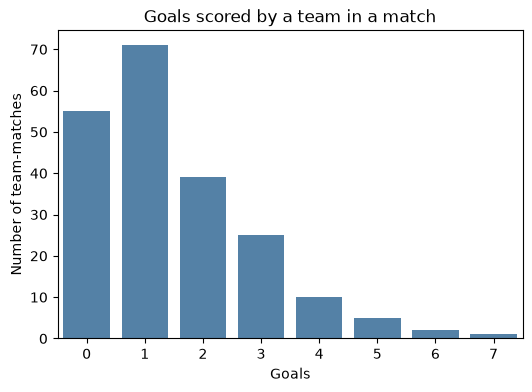

Mean: 1.48 | Std: 1.39 | Zero-goal games: 55


In [63]:
plt.figure(figsize=(6, 4))
sns.countplot(x='y_goals', data=df, color='steelblue')
plt.title('Goals scored by a team in a match')
plt.xlabel('Goals'); plt.ylabel('Number of team-matches')
plt.show()
print('Mean:', round(df['y_goals'].mean(), 2), '| Std:', round(df['y_goals'].std(), 2),
      '| Zero-goal games:', (df['y_goals'] == 0).sum())

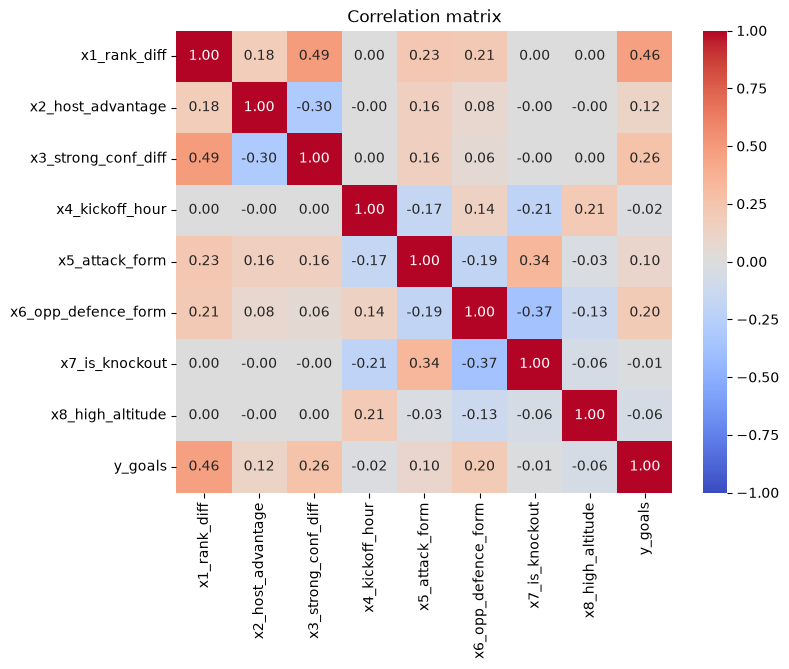

In [64]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[features + ['y_goals']].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.savefig('figures/fig_correlation.png', dpi=200, bbox_inches='tight')
plt.show()

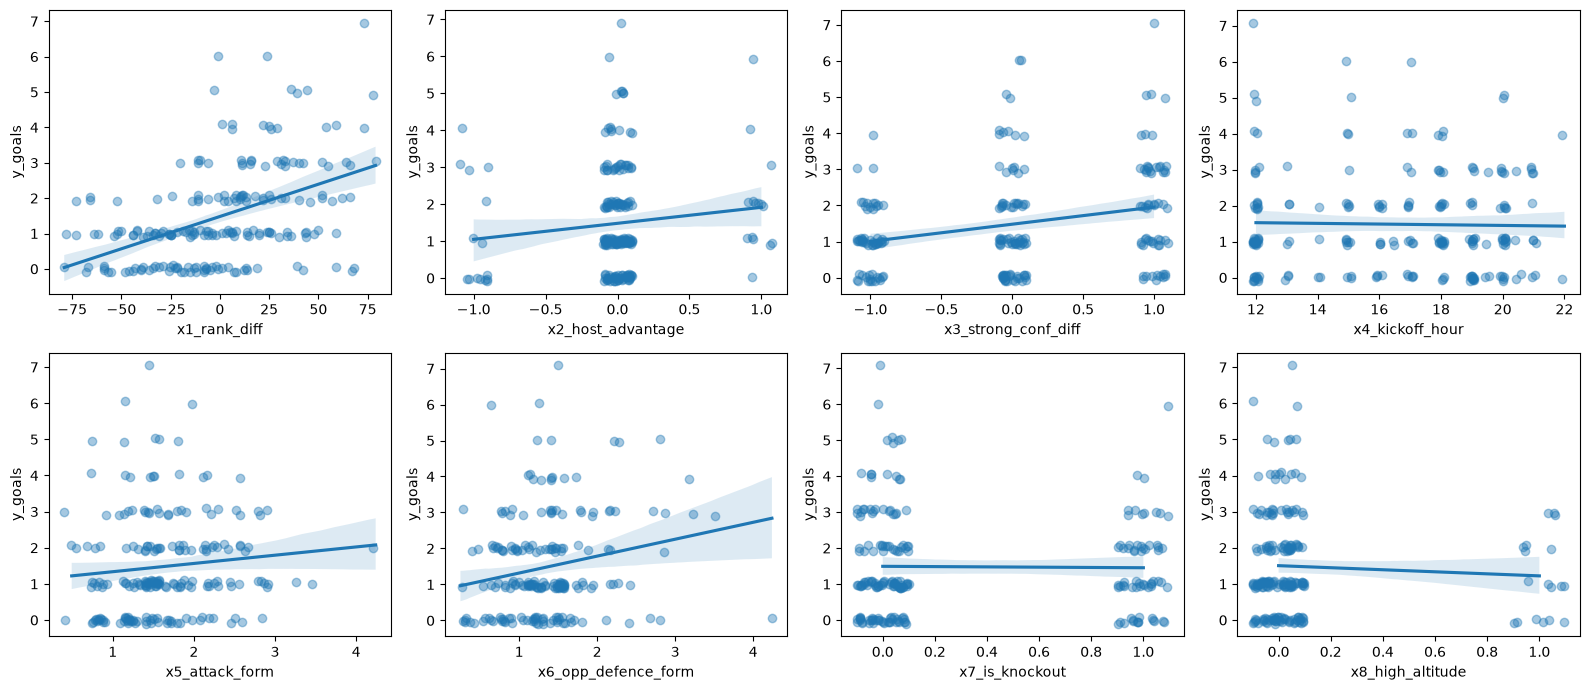

In [65]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, features):
    sns.regplot(x=col, y='y_goals', data=df, ax=ax, scatter_kws={'alpha': 0.4}, x_jitter=0.1, y_jitter=0.1)
plt.tight_layout()
plt.show()

### Checking multicollinearity (VIF)

In [66]:
def vif(X):
    X = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                     index=X.columns[1:]).round(2)

vif(df[features])

x1_rank_diff           1.66
x2_host_advantage      1.35
x3_strong_conf_diff    1.69
x4_kickoff_hour        1.11
x5_attack_form         1.29
x6_opp_defence_form    1.30
x7_is_knockout         1.30
x8_high_altitude       1.08
dtype: float64

All VIF values are low. We first tried FIFA pot as a variable, but it had VIF of about 7 together with rank
(pots are mostly decided by rank), so it was replaced with the altitude variable.
World Cup appearances was also left out (it is already in LR 2.1) to keep the shared variables safely under the limit.

## 6. Model 1 - linear regression with the 8 variables

**Important:** each match appears twice (once for each team), and the two rows mirror each other.
If one row is in training and the other is in testing, the model has partly seen the test match.
So all splits are done **by match** (GroupShuffleSplit / GroupKFold).

In [67]:
X = df[features]
y = df['y_goals']
groups = df['match_id']

model1 = sm.OLS(y, sm.add_constant(X)).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:                y_goals   R-squared:                       0.233
Model:                            OLS   Adj. R-squared:                  0.202
Method:                 Least Squares   F-statistic:                     7.568
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           8.13e-09
Time:                        22:28:41   Log-Likelihood:                -336.02
No. Observations:                 208   AIC:                             690.0
Df Residuals:                     199   BIC:                             720.1
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   1.3233    

### Evaluation: 80/20 train-test split (by match) and 10-fold cross-validation

In [68]:
def evaluate(X, y, name):
    # hold-out test: 80% of matches train, 20% test
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, test_idx = next(gss.split(X, y, groups))
    lr = LinearRegression().fit(X.iloc[train_idx], y.iloc[train_idx])
    pred_test = lr.predict(X.iloc[test_idx])
    baseline = np.full(len(test_idx), y.iloc[train_idx].mean())

    # 10-fold cross-validation (every row is predicted once)
    pred_cv = cross_val_predict(LinearRegression(), X, y, groups=groups, cv=GroupKFold(n_splits=10))

    rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
    return pd.Series({
        'Test MAE': mean_absolute_error(y.iloc[test_idx], pred_test),
        'Test RMSE': rmse(y.iloc[test_idx], pred_test),
        'Test R2': r2_score(y.iloc[test_idx], pred_test),
        'Baseline test RMSE': rmse(y.iloc[test_idx], baseline),
        'CV MAE': mean_absolute_error(y, pred_cv),
        'CV RMSE': rmse(y, pred_cv),
        'CV R2': r2_score(y, pred_cv),
    }, name=name).round(3)

results = [evaluate(X, y, 'Model 1')]
results[0]

Test MAE              0.966
Test RMSE             1.278
Test R2               0.239
Baseline test RMSE    1.468
CV MAE                0.971
CV RMSE               1.277
CV R2                 0.156
Name: Model 1, dtype: float64

The baseline always predicts the average goals from the training data. A useful model must beat it.

### Checking the regression assumptions

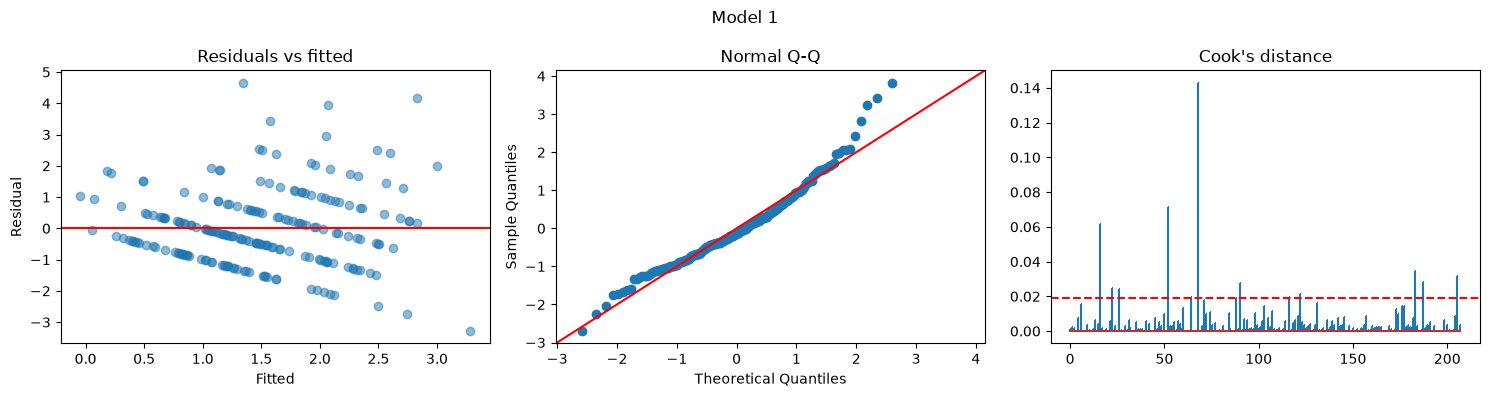

Influential rows (Cook > 4/n): 12


In [69]:
def diagnostics(model, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].scatter(model.fittedvalues, model.resid, alpha=0.5)
    axes[0].axhline(0, color='red'); axes[0].set_xlabel('Fitted'); axes[0].set_ylabel('Residual')
    axes[0].set_title('Residuals vs fitted')
    sm.qqplot(model.resid, line='45', fit=True, ax=axes[1]); axes[1].set_title('Normal Q-Q')
    cooks = model.get_influence().cooks_distance[0]
    axes[2].stem(cooks, markerfmt=','); axes[2].axhline(4 / len(cooks), color='red', ls='--')
    axes[2].set_title("Cook's distance")
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f"figures/fig_diagnostics_{title.replace(' ', '_').lower()}.png", dpi=200, bbox_inches='tight')
    plt.show()
    print('Influential rows (Cook > 4/n):', (cooks > 4 / len(cooks)).sum())

diagnostics(model1, 'Model 1')

Goals are small whole numbers (0, 1, 2 ...), so residuals form diagonal stripes and the Q-Q plot has a heavier right tail
(a few big wins such as 6-0 or 7-0). This is expected for count data and is a limitation of linear regression here.

## 7. Model 2 - improving the model

In LR 2.1 we saw that the effect of rank levels off for big rank gaps. Being ranked 1 vs 11 is a much bigger gap in
quality than 70 vs 80. So we replace the rank difference with the **log of the rank ratio**
`log(opponent rank / team rank)`. It is the same information (rank), just transformed, so the model still has 8 variables.

corr rank diff: 0.463
corr log rank ratio: 0.484


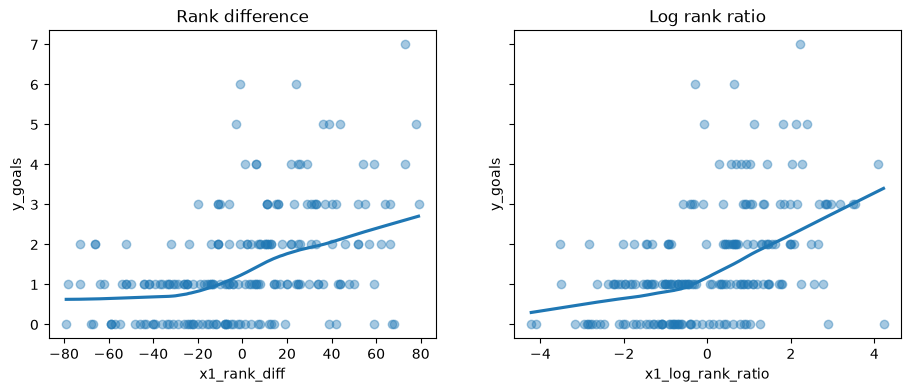

In [70]:
df['x1_log_rank_ratio'] = np.log(df['opponent'].map(team_info['fifa_rank']) / df['team'].map(team_info['fifa_rank']))

print('corr rank diff:', round(df['x1_rank_diff'].corr(df['y_goals']), 3))
print('corr log rank ratio:', round(df['x1_log_rank_ratio'].corr(df['y_goals']), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.regplot(x='x1_rank_diff', y='y_goals', data=df, ax=axes[0], lowess=True, scatter_kws={'alpha': 0.4})
sns.regplot(x='x1_log_rank_ratio', y='y_goals', data=df, ax=axes[1], lowess=True, scatter_kws={'alpha': 0.4})
axes[0].set_title('Rank difference'); axes[1].set_title('Log rank ratio')
plt.show()

In [71]:
features2 = ['x1_log_rank_ratio'] + features[1:]
X2 = df[features2]

model2 = sm.OLS(y, sm.add_constant(X2)).fit()
print(model2.summary())
print(vif(X2))

                            OLS Regression Results                            
Dep. Variable:                y_goals   R-squared:                       0.252
Model:                            OLS   Adj. R-squared:                  0.222
Method:                 Least Squares   F-statistic:                     8.380
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           8.68e-10
Time:                        22:28:41   Log-Likelihood:                -333.45
No. Observations:                 208   AIC:                             684.9
Df Residuals:                     199   BIC:                             714.9
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   1.4966    

In [72]:
results.append(evaluate(X2, y, 'Model 2'))
comparison = pd.DataFrame(results)
comparison['Adj R2 (full data)'] = [round(model1.rsquared_adj, 3), round(model2.rsquared_adj, 3)]
comparison.to_csv('figures/results_table.csv')
comparison

,Test MAE,Test RMSE,Test R2,Baseline test RMSE,CV MAE,CV RMSE,CV R2,Adj R2 (full data)
Model 1,0.966,1.278,0.239,1.468,0.971,1.277,0.156,0.202
Model 2,0.947,1.263,0.256,1.468,0.935,1.261,0.177,0.222


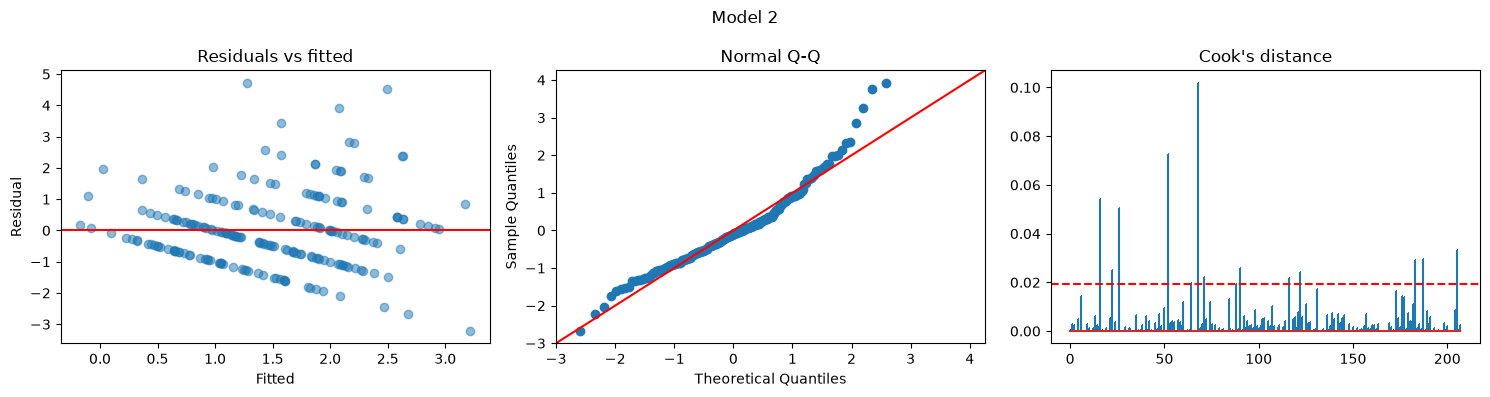

Influential rows (Cook > 4/n): 13


In [73]:
diagnostics(model2, 'Model 2')

In [74]:
# coefficients of the final model with 95% confidence intervals
coef = pd.concat([model2.params, model2.conf_int(), model2.pvalues], axis=1)
coef.columns = ['coef', 'CI low', 'CI high', 'p-value']
coef.round(3).to_csv('figures/coefficients_model2.csv')
coef.round(3)

,coef,CI low,CI high,p-value
const,1.497,0.273,2.720,0.017
x1_log_rank_ratio,0.363,0.230,0.495,0.000
x2_host_advantage,0.343,-0.154,0.841,0.175
x3_strong_conf_diff,0.121,-0.165,0.407,0.406
x4_kickoff_hour,-0.012,-0.069,0.046,0.691
x5_attack_form,-0.061,-0.378,0.256,0.704
x6_opp_defence_form,0.203,-0.123,0.529,0.222
x7_is_knockout,0.060,-0.355,0.475,0.775
x8_high_altitude,-0.199,-0.822,0.423,0.529


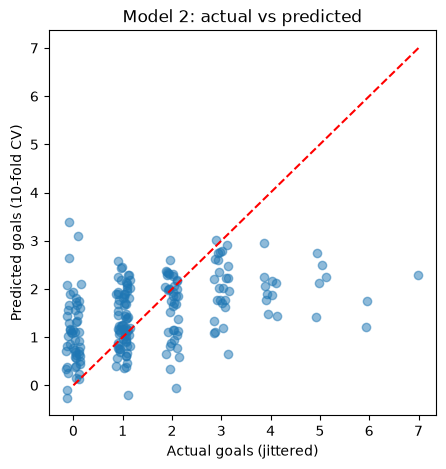

In [75]:
pred_cv = cross_val_predict(LinearRegression(), X2, y, groups=groups, cv=GroupKFold(n_splits=10))
plt.figure(figsize=(5, 5))
plt.scatter(y + np.random.uniform(-0.15, 0.15, len(y)), pred_cv, alpha=0.5)
plt.plot([0, 7], [0, 7], 'r--')
plt.xlabel('Actual goals (jittered)'); plt.ylabel('Predicted goals (10-fold CV)')
plt.title('Model 2: actual vs predicted')
plt.savefig('figures/fig_actual_vs_predicted.png', dpi=200, bbox_inches='tight')
plt.show()